# Page Rank



In [1]:
from pyspark import SparkConf, SparkContext

sc = SparkContext.getOrCreate(SparkConf())

In [2]:
def f(x):
    links=x[1][0]
    rank=x[1][1]
    n=len(links.split(","))
    result=[]
    for s in links.split(","):
        result.append((s,rank*1.0/n))
    return result

## Example： 
pagerank1.txt

|page rank data|
|:---- |
|A:B,C,D |
|B:A,D |
|C:A |
|D:B,C |
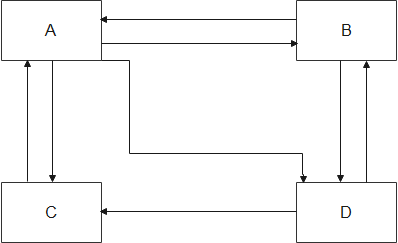

In [3]:
file="data/pagerank1.txt"

data=sc.textFile(file)

link=data.map(lambda x:(x.split(":")[0],x.split(":")[1])).cache()

for x in link.collect():
    print(x)

rank=link.mapValues(lambda x:1.0)
for r in rank.collect():
    print(r)
    
for i in range(10):
    rank=link.join(rank).flatMap(f).reduceByKey(lambda x,y:x+y).mapValues(lambda x:0.15+0.85*x).cache()
    
#for r in rank.collect(): 
#    print(r)   

('A', 'B,C,D')
('B', 'A,D')
('C', 'A')
('D', 'B,C')
('A', 1.0)
('B', 1.0)
('C', 1.0)
('D', 1.0)


In [4]:
#output result
rank.sortByKey().collect()

[('A', 1.298188273285468),
 ('B', 0.9006039089048439),
 ('C', 0.9006039089048439),
 ('D', 0.9006039089048439)]